# 03 · Sensitivity to the signal window

**Why this notebook.** In notebook 02 the signal uses the last **10 seconds** of each minute, and the variance ratio was measured at 10 seconds, 1, 5 and 60 minutes. Two questions remained open:

1. Does momentum already exist at horizons shorter than 10 seconds (2, 5 seconds)?
2. Is the result specific to the 10-second window? If only 10 seconds worked, the choice could look cherry-picked. If nearby windows give similar results, the finding does not depend on that choice.

To answer them I re-download the 1-second data and, for every minute, compute the return over the last **2, 5, 10, 20 and 30 seconds**, plus the variance ratio at 2, 5, 10, 20, 30 and 60 seconds for every month. The main strategy stays at 10 seconds; this notebook is a robustness check only.

**Part A** downloads and processes the data (about 20–30 minutes, one month at a time in memory, about 2 MB saved per month). **Part B** analyses it.

In [1]:
import os, io, zipfile, hashlib, subprocess, time
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt

BASE_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1s/"
COLS = ["open_time", "open", "high", "low", "close", "volume", "close_time",
        "quote_volume", "trades", "taker_buy_base", "taker_buy_quote", "ignore"]
MONTHS = [p.strftime("%Y-%m") for p in pd.period_range("2023-01", "2026-10", freq="M")]
WINDOWS = [2, 5, 10, 20, 30]          # signal windows in seconds
VR_Q = [2, 5, 10, 20, 30, 60]         # variance-ratio horizons in seconds
OUT = "data_windows"
os.makedirs(OUT, exist_ok=True)
try:   # keep a Mac awake while this notebook runs
    subprocess.Popen(["caffeinate", "-dims", "-w", str(os.getpid())])
except Exception:
    pass

## Part A · Download and process

For each month: download the zip, verify the SHA-256 checksum, fill missing seconds with the last price, then keep one row per minute with the log close and the return over the last $k$ seconds,
$$r^{(k)}_t = \ln P_{t,\,59s} - \ln P_{t,\,59s-k}.$$
The variance ratio at horizon $q$ seconds uses overlapping $q$-second returns, $VR(q) = \mathrm{Var}(r^{(q)}) / (q \cdot \mathrm{Var}(r^{(1)}))$. Months already processed are skipped, so the loop can be restarted safely.

In [2]:
def download_month(month):
    url = f"{BASE_URL}BTCUSDT-1s-{month}.zip"
    r = requests.get(url, timeout=900)
    r.raise_for_status()
    official = requests.get(url + ".CHECKSUM", timeout=60).text.split()[0]
    ok = official == hashlib.sha256(r.content).hexdigest()
    z = zipfile.ZipFile(io.BytesIO(r.content))
    raw = pd.read_csv(z.open(z.namelist()[0]), header=None, names=COLS, usecols=["open_time", "close"])
    return raw, ok

def process_windows(raw):
    df = raw[["open_time", "close"]].copy()
    unit = "us" if df["open_time"].iloc[0] > 1e14 else "ms"       # Binance switched to microseconds in 2025
    df["time"] = pd.to_datetime(df["open_time"], unit=unit)
    df = df.drop_duplicates("time").set_index("time").sort_index()
    full = pd.date_range(df.index[0].floor("1min"), df.index[-1].floor("1min") + pd.Timedelta(seconds=59), freq="1s")
    lp = np.log(df["close"].reindex(full).ffill().bfill())        # missing seconds keep the last price
    out = pd.DataFrame({"log_close": lp.resample("1min").last()})
    for k in WINDOWS:
        out[f"ret_last{k}s"] = lp.resample("1min").last() - lp.shift(k).resample("1min").last()
    r1 = lp.diff().dropna()
    stats = {f"VR_{q}s": lp.diff(q).dropna().var() / (q * r1.var()) for q in VR_Q}
    stats["ac1_1s"] = r1.autocorr(1)
    return out, stats

In [3]:
stats_file = f"{OUT}/vr_by_month.csv"
all_stats = pd.read_csv(stats_file).to_dict("records") if os.path.exists(stats_file) else []
done = {s["month"] for s in all_stats}
t0 = time.time()
for month in MONTHS:
    path = f"{OUT}/BTCUSDT-windows-{month}.parquet"
    if month in done and os.path.exists(path):
        continue
    raw, ok = download_month(month)
    out, st = process_windows(raw)
    out.to_parquet(path)
    st.update({"month": month, "checksum_ok": ok})
    all_stats = [s for s in all_stats if s["month"] != month] + [st]
    pd.DataFrame(all_stats).sort_values("month").to_csv(stats_file, index=False)
    print(f"{month}  checksum {ok}  rows {len(out):,}  VR_5s {st['VR_5s']:.2f}  elapsed {(time.time()-t0)/60:.1f} min")
    del raw, out
print("done")

2023-01  checksum True  rows 44,640  VR_5s 0.95  elapsed 0.2 min
2023-02  checksum True  rows 40,320  VR_5s 0.98  elapsed 0.5 min
2023-03  checksum True  rows 44,640  VR_5s 1.01  elapsed 0.7 min
2023-04  checksum True  rows 43,200  VR_5s 1.24  elapsed 0.9 min
2023-05  checksum True  rows 44,640  VR_5s 1.23  elapsed 1.1 min
2023-06  checksum True  rows 43,200  VR_5s 1.24  elapsed 1.2 min
2023-07  checksum True  rows 44,640  VR_5s 1.32  elapsed 1.4 min
2023-08  checksum True  rows 44,640  VR_5s 1.23  elapsed 1.6 min
2023-09  checksum True  rows 43,200  VR_5s 1.24  elapsed 1.8 min
2023-10  checksum True  rows 44,640  VR_5s 1.21  elapsed 1.9 min
2023-11  checksum True  rows 43,200  VR_5s 1.26  elapsed 2.1 min
2023-12  checksum True  rows 44,640  VR_5s 1.29  elapsed 2.3 min
2024-01  checksum True  rows 44,640  VR_5s 1.24  elapsed 2.5 min
2024-02  checksum True  rows 41,760  VR_5s 1.29  elapsed 2.7 min
2024-03  checksum True  rows 44,640  VR_5s 1.24  elapsed 2.9 min
2024-04  checksum True  r

## Part B · Analysis
### B1 · Variance ratio at short horizons
Median across months, before and after the end of zero-fee trading (22 March 2023; April 2023 onwards is used as the post-break sample).

In [4]:
vr = pd.read_csv(stats_file).set_index("month").sort_index()
print("all checksums OK:", bool(vr["checksum_ok"].all()), "| months:", len(vr))
vr_cols = [f"VR_{q}s" for q in VR_Q]
pre, post = vr.loc[:"2023-02"], vr.loc["2023-04":]
vr_table = pd.DataFrame({"zero-fee period (Jan-Feb 2023)": pre[vr_cols].median(),
                         "after the break, median month": post[vr_cols].median(),
                         "after the break, share of months above 1": (post[vr_cols] > 1).mean()}).T
vr_table.round(3)

all checksums OK: True | months: 46


,VR_2s,VR_5s,VR_10s,VR_20s,VR_30s,VR_60s
zero-fee period (Jan-Feb 2023),0.963,0.966,0.965,0.964,0.967,0.978
"after the break, median month",1.116,1.263,1.342,1.415,1.445,1.501
"after the break, share of months above 1",0.977,0.977,1.000,1.000,1.000,1.000


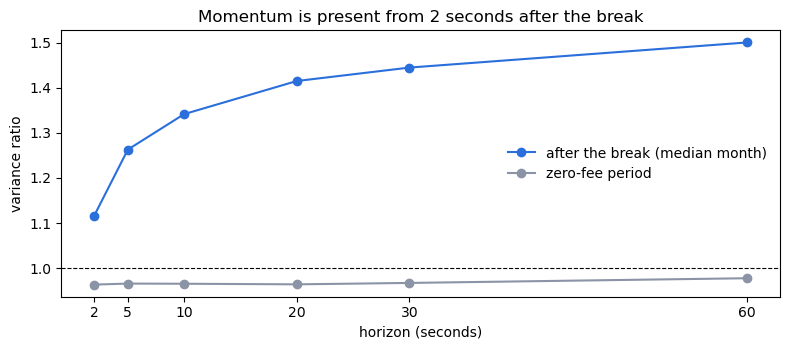

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(VR_Q, post[vr_cols].median().values, "o-", color="#2a6fdb", label="after the break (median month)")
ax.plot(VR_Q, pre[vr_cols].median().values, "o-", color="#8a94a6", label="zero-fee period")
ax.axhline(1, color="black", lw=0.8, ls="--")
ax.set_xlabel("horizon (seconds)"); ax.set_ylabel("variance ratio"); ax.set_xticks(VR_Q)
ax.set_title("Momentum is present from 2 seconds after the break"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("fig_6_vr_short.png", bbox_inches="tight", dpi=150); plt.show()

### B2 · Strategy with different signal windows
Same rule as notebook 02 for every window $k$: at each minute close take the sign of the last-$k$-second return and hold that position for the next minute. Same conventions (1× notional, not compounded, before costs) and the same periods, in-sample 2023–24 and out-of-sample 2025–Oct 2026.

In [6]:
import statsmodels.api as sm
w = pd.concat([pd.read_parquet(f"{OUT}/BTCUSDT-windows-{m}.parquet") for m in MONTHS]).sort_index()
w = w[~w.index.duplicated()]
fwd = w["log_close"].diff().shift(-1)            # next minute's log return
MIN_PER_YEAR = 525_600
periods = {"2023-24 (in-sample)": w.index < "2025-01-01", "2025-Oct 2026 (out-of-sample)": w.index >= "2025-01-01"}
rows = []
for pname, mask in periods.items():
  for k in WINDOWS:
    pos = np.sign(w[f"ret_last{k}s"]).fillna(0)
    pnl = (pos * fwd).fillna(0)
    if True:
        p, ps = pnl[mask], pos[mask]
        hac = sm.OLS(p.values * 1e4, np.ones(len(p))).fit(cov_type="HAC", cov_kwds={"maxlags": 60})
        nz = p[p != 0]
        rows.append({"window": f"last {k}s", "period": pname,
                     "avg bp per minute": p.mean() * 1e4,
                     "Newey-West t": hac.tvalues[0],
                     "breakeven cost (bp)": p.sum() / ps.diff().abs().sum() * 1e4,
                     "hit rate (non-zero min)": (nz > 0).mean(),
                     "Sharpe (ann.)": p.mean() / p.std() * np.sqrt(MIN_PER_YEAR)})
window_table = pd.DataFrame(rows).set_index(["period", "window"])
window_table.round(3)

avg bp per minute  Newey-West t  \
period                        window                                      
2023-24 (in-sample)           last 2s               0.114        19.037   
                              last 5s               0.160        25.138   
                              last 10s              0.167        25.384   
                              last 20s              0.144        22.014   
                              last 30s              0.124        19.311   
2025-Oct 2026 (out-of-sample) last 2s               0.147        26.230   
                              last 5s               0.181        29.660   
                              last 10s              0.187        29.928   
                              last 20s              0.157        25.273   
                              last 30s              0.131        20.779   

                                        breakeven cost (bp)  \
period                        window                          
2023-24 (in-sample)           last 2s                 0.133   
                              last 5s                 0.176   
                              last 10s                0.179   
                              last 20s                0.150   
                              last 30s                0.129   
2025-Oct 2026 (out-of-sample) last 2s                 0.176   
                              last 5s                 0.203   
                              last 10s                0.200   
                              last 20s                0.163   
                              last 30s                0.134   

                                        hit rate (non-zero min)  Sharpe (ann.)  
period                        window                                            
2023-24 (in-sample)           last 2s                     0.500         13.603  
                              last 5s                     0.507         18.177  
                              last 10s                    0.510         18.585  
                              last 20s                    0.510         15.760  
                              last 30s                    0.509         13.501  
2025-Oct 2026 (out-of-sample) last 2s                     0.509         19.515  
                              last 5s                     0.514         22.779  
                              last 10s                    0.515         22.716  
                              last 20s                    0.512         18.737  
                              last 30s                    0.509         15.515

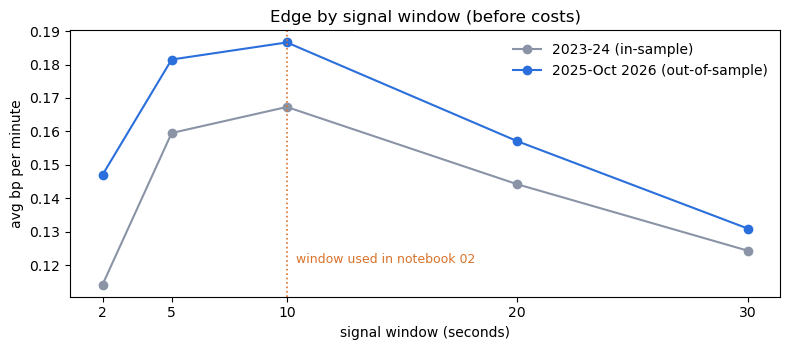

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for (pname, grp), col in zip(window_table.groupby(level=0, sort=False), ["#8a94a6", "#2a6fdb"]):
    ax.plot(WINDOWS, grp["avg bp per minute"].values, "o-", color=col, label=pname)
ax.axvline(10, color="#d9732b", ls=":", lw=1.2)
ax.text(10.4, ax.get_ylim()[0] + 0.01, "window used in notebook 02", color="#d9732b", fontsize=9)
ax.set_xlabel("signal window (seconds)"); ax.set_ylabel("avg bp per minute"); ax.set_xticks(WINDOWS)
ax.set_title("Edge by signal window (before costs)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("fig_7_windows.png", bbox_inches="tight", dpi=150); plt.show()

### Reading the results

1. **Momentum starts within two seconds.** After the break, the median monthly variance ratio is already 1.12 at 2 seconds and rises steadily, 1.26 at 5 seconds, 1.34 at 10 seconds and 1.50 at 60 seconds. It is above 1 in every month at 10 seconds and longer, and in all but one month at 2 and 5 seconds. In the zero-fee period it is slightly below 1 at every horizon.
2. **Window selection.** Choosing the window on in-sample data alone (2023–24) gives 10 seconds. Out-of-sample (2025–Oct 2026), 10 seconds is again in the best range, so the 10-second window used in notebook 02 is supported by the data.
3. **The result does not depend on the exact choice.** Every window from 2 to 30 seconds is profitable before costs in both periods, with Newey-West t-statistics between 19 and 30.
4. **Shape.** The edge is highest for 5 to 10 seconds (0.18–0.19 bp per minute out-of-sample, a small difference relative to estimation error) and declines gradually for shorter and longer windows. Very short windows contain fewer price changes and more noise; longer windows include older moves that are already priced in.
5. **Consistency check.** The 10-second results reproduce notebook 02 exactly (0.167 and 0.187 bp per minute), which confirms both pipelines.

In [8]:
oos = window_table.xs("2025-Oct 2026 (out-of-sample)")["avg bp per minute"]
ins = window_table.xs("2023-24 (in-sample)")["avg bp per minute"]
print("Out-of-sample edge by window (bp per minute):", oos.round(3).to_dict())
print("Best window in-sample:", ins.idxmax(), "| best window out-of-sample:", oos.idxmax())
print("All windows positive in both periods:", bool((ins > 0).all() and (oos > 0).all()))
print("10s edge relative to the best window, out-of-sample: {:.0%}".format(oos["last 10s"] / oos.max()))

Out-of-sample edge by window (bp per minute): {'last 2s': 0.147, 'last 5s': 0.181, 'last 10s': 0.187, 'last 20s': 0.157, 'last 30s': 0.131}
Best window in-sample: last 10s | best window out-of-sample: last 10s
All windows positive in both periods: True
10s edge relative to the best window, out-of-sample: 100%
